In [1]:
import sys

sys.path.append("../src")
from pipeline import historical_data_preparation_pipeline, daily_data_preparation_pipeline
from functions import historical_feature_generation
import pandas as pd
import numpy as np
from scipy.special import expit
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/whoop_fitness_dataset_100k.csv")


functions.py imported successfully
pipeline.py imported successfully


In [2]:
from sklearn.model_selection import GroupShuffleSplit

# Keep recovery_score temporarily for historical feature generation
data = df.copy()

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

# splits by user id (80/20), get their indexes
train_idx, test_idx = next(
    gss.split(
        data,
        data["recovery_score"],
        groups=data["user_id"]
    )
)

# grab the users' data based on indexes
train_data = data.iloc[train_idx].copy()
test_data = data.iloc[test_idx].copy()

# Separate target AFTER splitting
y_train = train_data["recovery_score"]
y_test = test_data["recovery_score"]

y_test.to_csv("../data/y_test.csv", index=False)

# Keep recovery_score temporarily in X, it will be later drop in the pipeline
x_train = train_data.copy()
x_test = test_data.copy()

In [3]:
x_train_processed = historical_data_preparation_pipeline.fit_transform(
    x_train,
    y_train,
    feature_selection__groups=x_train["user_id"] # tell the feature selection transformer to group using user id
)

x_test_processed = historical_data_preparation_pipeline.transform(
    x_test
)

In [4]:
# print out the selected/survived features
rfecv = historical_data_preparation_pipeline.named_steps["feature_selection"] 

feature_names = rfecv.feature_names_in_

selected_features = feature_names[rfecv.support_]

print("Number of selected features:", len(selected_features))
print(selected_features)

Number of selected features: 64
['activity_type_CrossFit' 'activity_type_Cycling' 'activity_type_HIIT'
 'activity_type_Running' 'activity_type_Weight Training'
 'activity_type_Yoga' 'fitness_level' 'age' 'weight_kg' 'height_cm'
 'day_strain' 'sleep_efficiency' 'light_sleep_hours' 'hrv'
 'resting_heart_rate' 'hrv_baseline' 'rhr_baseline' 'respiratory_rate'
 'skin_temp_deviation' 'calories_burned' 'activity_duration_min'
 'activity_strain' 'activity_calories' 'hr_zone_1_min' 'hr_zone_2_min'
 'hr_zone_3_min' 'hr_zone_5_min' 'high_intensity_min' 'low_intensity_min'
 'hrv_ratio' 'rhr_ratio' 'rem_sleep_hours_ratio' 'deep_sleep_hours_ratio'
 'bmi' 'month' 'month_sin' 'month_cos' 'day_of_week_num'
 'sleep_quality_score' 'hrv_rhr_ratio' 'hrv_deviation' 'rhr_deviation'
 'strain_sleep_ratio' 'day_strain_rolling_mean_7d'
 'sleep_hours_rolling_mean_7d' 'hrv_rolling_mean_7d'
 'previous_recovery_score' 'previous_sleep_hours'
 'previous_sleep_efficiency' 'previous_resting_heart_rate'
 'day_strain_chan

In [5]:
# print out the removed features
removed_features = feature_names[~rfecv.support_]

print("Removed features:")
print(removed_features)

Removed features:
['gender_Female' 'gender_Male' 'activity_type_Rest Day'
 'activity_type_Swimming' 'activity_type_Walking' 'sleep_hours'
 'sleep_performance' 'rem_sleep_hours' 'deep_sleep_hours' 'wake_ups'
 'time_to_fall_asleep_min' 'workout_completed' 'avg_heart_rate'
 'max_heart_rate' 'hr_zone_4_min' 'day_of_week_sin' 'day_of_week_cos'
 'is_weekend' 'previous_day_strain' 'previous_hrv'
 'previous_calories_burned' 'sleep_efficiency_change'
 'hrv_sleep_interaction' 'is_first_record']


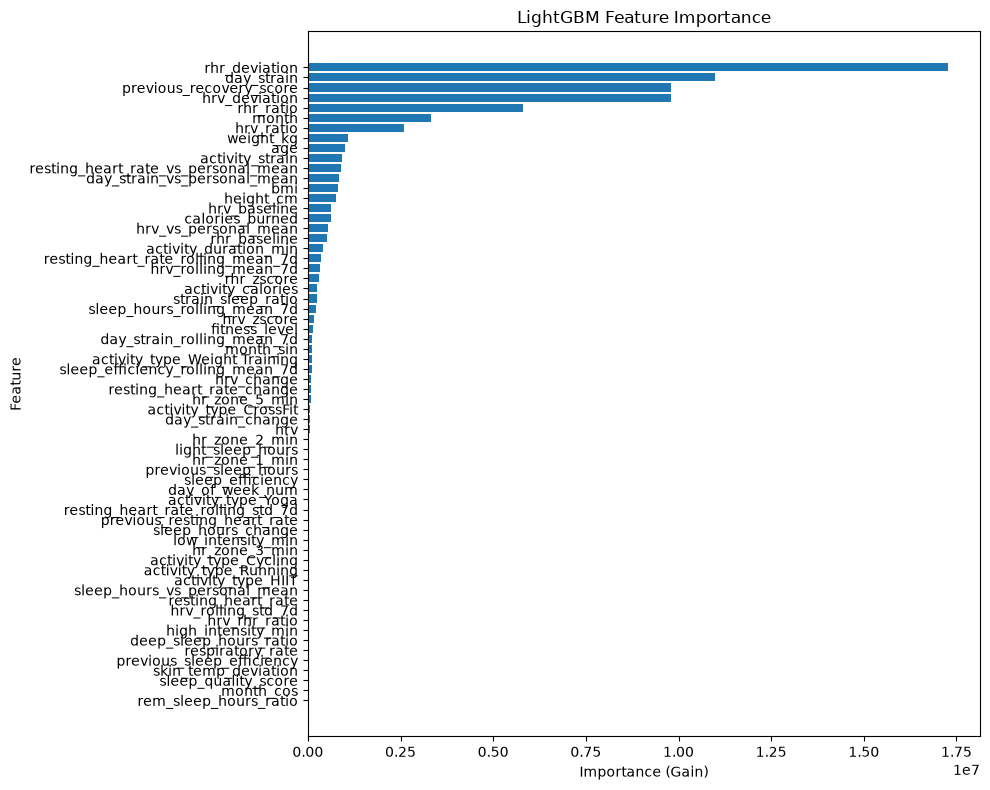

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

rfecv = historical_data_preparation_pipeline.named_steps["feature_selection"]

# Estimator used by RFECV (LGBMREgressor)
estimator = rfecv.estimator_

feature_names = rfecv.feature_names_in_
selected_features = feature_names[rfecv.support_]

importance = estimator.feature_importances_

importance_df = pd.DataFrame({
    "feature": selected_features,
    "importance": importance
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    importance_df["feature"],
    importance_df["importance"]
)

plt.xlabel("Importance (Gain)")
plt.ylabel("Feature")
plt.title("LightGBM Feature Importance")
plt.tight_layout()

plt.show()

In [7]:
from sklearn.tree import DecisionTreeRegressor

# Decision Tree Regressor
dtr = DecisionTreeRegressor( random_state=42 )

dtr.fit(x_train_processed, y_train)

predict_dtr = dtr.predict(x_test_processed)
predict_dtr = np.clip(predict_dtr, 0, 100)
pd.DataFrame(predict_dtr, columns=["prediction"]).to_csv("../data/predict_dtr.csv", index=False)

from sklearn.ensemble import HistGradientBoostingRegressor

# HistGradient Boosting Regressor
hgbr = HistGradientBoostingRegressor( random_state=42 )

hgbr.fit(x_train_processed, y_train)

predict_hgbr = hgbr.predict(x_test_processed)
predict_hgbr = np.clip(predict_hgbr, 0, 100)
pd.DataFrame(predict_hgbr, columns=["prediction"]).to_csv("../data/predict_hgbr.csv", index=False)

# XGBoost Regressor
from xgboost import XGBRegressor

xgbr = XGBRegressor( random_state=42 )

xgbr.fit(x_train_processed, y_train)

predict_xgbr = xgbr.predict(x_test_processed)
predict_xgbr = np.clip(predict_xgbr, 0, 100)
pd.DataFrame(predict_xgbr, columns=["prediction"]).to_csv("../data/predict_xgbr.csv", index=False)

# LGBM Regressor
from lightgbm import LGBMRegressor

lgbm = LGBMRegressor( random_state=42 )

lgbm.fit(x_train_processed, y_train)

predict_lgbm = lgbm.predict(x_test_processed)
predict_lgbm  = np.clip(predict_lgbm , 0, 100)
pd.DataFrame(predict_lgbm, columns=["prediction"]).to_csv("../data/predict_lgbm.csv", index=False)

In [8]:
from scipy.stats import randint, uniform

# parameters range of each models
param_dtr = {
    "max_depth": randint(3, 20),
    "min_samples_leaf": randint(2, 20),
    "min_samples_split": randint(2, 20)
}

param_rtr = {
    "n_estimators": randint(50, 200),
    "max_depth": randint(5, 15),
    "min_samples_leaf": randint(5, 20)
}

param_hgbr = {
    "max_iter": randint(100, 300),
    "max_leaf_nodes": randint(15, 60),
    "learning_rate": uniform(0.01, 0.19),
    "min_samples_leaf": randint(10, 30),
    "l2_regularization": uniform(0, 1)
}

param_xgbr = {
    "n_estimators": randint(100, 300),
    "max_depth": randint(2, 8),
    "learning_rate": uniform(0.01, 0.19),
    "subsample": uniform(0.7, 0.3),
    "colsample_bytree": uniform(0.6, 0.4)
}

param_lgbm = {
    "n_estimators": randint(100, 300),
    "num_leaves": randint(15, 60),
    "learning_rate": uniform(0.01, 0.2),
    "subsample": uniform(0.7, 0.3),
    "colsample_bytree": uniform(0.6, 0.4)
}

# Hypertuning
from sklearn.model_selection import GroupKFold, RandomizedSearchCV

cv = GroupKFold(n_splits=5, shuffle=True, random_state=42)

models_and_params = {
    "Decision Tree Regressor": (DecisionTreeRegressor(random_state=42), param_dtr),
    "Gradient Boosting Regressor": (HistGradientBoostingRegressor(random_state=42), param_hgbr),
    "XGBoost Regressor": (XGBRegressor(random_state=42), param_xgbr),
    "LGBM Regressor": (LGBMRegressor(random_state=42, verbose=-1), param_lgbm),
}

best_model_params = []

for name, (model, params) in models_and_params.items():
    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=params,
        n_iter= 30,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        random_state=42,
        verbose=1
    )
    search.fit(x_train_processed, y_train, groups=x_train['user_id'])
    
    best_model_params.append(
        {"model_name": name, "best_params": search.best_params_}
    )

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Fitting 5 folds for each of 30 candidates, totalling 150 fits


In [9]:
import json

dtr_tuned_params = best_model_params[0]["best_params"]
hgbr_tuned_params = best_model_params[1]["best_params"]
xgbr_tuned_params = best_model_params[2]["best_params"]
lgbm_tuned_params = best_model_params[3]["best_params"]

# save those tuned parameters as json for model evaluation
with open("../json/dtr_tuned_params.json", "w") as f:
    json.dump(dtr_tuned_params, f, indent=4)
    
with open("../json/hgbr_tuned_params.json", "w") as f:
    json.dump(hgbr_tuned_params, f, indent=4)
    
with open("../json/xgbr_tuned_params.json", "w") as f:
    json.dump(xgbr_tuned_params, f, indent=4)
    
with open("../json/lgbm_tuned_params.json", "w") as f:
    json.dump(lgbm_tuned_params, f, indent=4)

In [10]:
# tuned Decision Tree Regressor
dtr_tuned = DecisionTreeRegressor(**dtr_tuned_params, random_state=42)

dtr_tuned.fit(x_train_processed, y_train)

predict_dtr_tuned = dtr_tuned.predict(x_test_processed)
predict_dtr_tuned = np.clip(predict_dtr_tuned, 0, 100)
pd.DataFrame(predict_dtr_tuned, columns=["prediction"]).to_csv("../data/predict_dtr_tuned.csv", index=False)

# tuned HistGradient Boosting Regressor
hgbr_tuned = HistGradientBoostingRegressor(**hgbr_tuned_params, random_state=42)

hgbr_tuned.fit(x_train_processed, y_train)

predict_hgbr_tuned = hgbr_tuned.predict(x_test_processed)
predict_hgbr_tuned = np.clip(predict_hgbr_tuned, 0, 100)
pd.DataFrame(predict_hgbr_tuned, columns=["prediction"]).to_csv("../data/predict_hgbr_tuned.csv", index=False)


# tuned XGBoost Regressor
xgbr_tuned = XGBRegressor(**xgbr_tuned_params, random_state=42)

xgbr_tuned.fit(x_train_processed, y_train)

predict_xgbr_tuned = xgbr_tuned.predict(x_test_processed)
predict_xgbr_tuned = np.clip(predict_xgbr_tuned, 0, 100)
pd.DataFrame(predict_xgbr_tuned, columns=["prediction"]).to_csv("../data/predict_xgbr_tuned.csv", index=False)


# tuned LGBM Regressor
lgbm_tuned = LGBMRegressor(**lgbm_tuned_params, random_state=42)

lgbm_tuned.fit(x_train_processed, y_train)

predict_lgbm_tuned = lgbm_tuned.predict(x_test_processed)
predict_lgbm_tuned = np.clip(predict_lgbm_tuned, 0, 100)
pd.DataFrame(predict_lgbm_tuned, columns=["prediction"]).to_csv("../data/predict_lgbm_tuned.csv", index=False)